Sweeps the aperture radius **R** (via f-number `fn=[5,10,25,50]`) at fixed mirror separation `L=0`, comparing on-axis and transverse focal intensity across aperture sizes.

Companion notebook: `axiconUR_sweep_L.ipynb` sweeps mirror separation `L` instead, at a fixed f-number, and also compares the Taylor vs. exact sagitta approximation.

Equations for the axiparabola are taken from:

M. V. Ambat, J. L. Shaw, J. J. Pigeon, K. G. Miller, T. T. Simpson, D. H. Froula, and J. P. Palastro, "Programmable-trajectory ultrafast flying focus pulses," Opt. Express 31, 31354-31368 (2023)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv

font = {"size": 26}

plt.rc("font", **font)
plt.rcParams["figure.figsize"] = (20, 9)
plt.rcParams["lines.linewidth"] = 3
plt.rcParams["legend.fontsize"] = 20

# The Discrete Hankel Transform

In [2]:
def DHTarrays(N, R, ell):
    Zeroes = np.genfromtxt("BesselZeroes" + str(ell) + ".csv")
    r = R * Zeroes[:N] / Zeroes[N - 1]
    k = Zeroes[:N] / R
    return np.array([r, k])

def DHTtransformMatrix(N, R, ell):
    Zeroes = np.genfromtxt("BesselZeroes" + str(ell) + ".csv")
    alpha = Zeroes[:N]
    kR = alpha[N - 1]
    kmax = kR / R
    T = (
        jv(ell, np.outer(alpha, alpha) / kR)
        / np.outer(abs(jv(ell + 1, alpha)), abs(jv(ell + 1, alpha)))
        / kR
    )
    # print(T)
    A = abs(jv(ell + 1, alpha))
    T_R2K = 4.0 * np.pi * (R / kmax) * T * A[:, None] / A[None, :]
    T_K2R = (1 / np.pi) * (kmax / R) * T * A[:, None] / A[None, :]

    return T_R2K, T_K2R

# Propagation

Propagates incident beam `phi_I` over `z` after reflecting from the mirror `zm`using DHT

In [3]:
def forward_propagation(k, phi_I, T_R2K, T_K2R, z, zm, wavelength):
    k0 = 2 * np.pi / wavelength
    phi_R0 = phi_I * np.exp(-2j * k0 * zm) #reflected profile from mirror

    # Hankel transform the field through multiplying by the appropriate transform matrix
    FT = T_R2K @ phi_R0
    # Propagate phi_R0 over z through multiplying phi_R0 by the diffractive phase:
    FT = FT * np.exp(-1j * k**2 / (2 * k0) * z[:, np.newaxis])
    # Inverse Hankel transform 𝐸̃ from 𝑘𝑟-space to 𝑟-space through multiplying by the inverse transform matrix
    fT = T_K2R @ (FT.T)

    return fT

# Sagitta Function
$s_f(r)=\frac{R^2}{4L}\ln\left[1+\frac{L}{f_0}\left(\frac{r}{R}\right)^2\right]$


In [4]:
def create_axiparabola(r,R,L,f0,taylor=True):
    if taylor:
        sag = r**2/(4*f0)*(1-L/(2*f0)*(r/R)**2)
    else:
        sag = R**2/(4*L)*np.log(1+L/f0 *(r/R)**2)
    return sag

# Parameters

In [5]:
f = 0.5  # focal length of lens
ell = 0  # order of Bessel J function
wl=1e-6
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
L=0
# zR = np.pi * w0**2 / wl  # Initial rayleigh length
# print(zR)
# print(wl*f**2/(np.pi*R**2))
nr=5000
fn=np.array([5,10,25,50])
R= f / (4 * fn)
wf = 2 / np.pi *fn * wl
zR= np.pi * wf**2 / wl

# print "fn: fn, R: R, wf: wf, zR: zR" as a table with %.2e format 
print("fn\tR\t\twf\t\tzR\t\tdr<wf")
for i in range(len(fn)):
    print("%d\t%.2e\t%.2e\t%.2e\t%s" % (fn[i], R[i], wf[i], zR[i], str(R[i]/nr<wf[i])))

fn	R		wf		zR		dr<wf
5	2.50e-02	3.18e-06	3.18e-05	False
10	1.25e-02	6.37e-06	1.27e-04	True
25	5.00e-03	1.59e-05	7.96e-04	True
50	2.50e-03	3.18e-05	3.18e-03	True


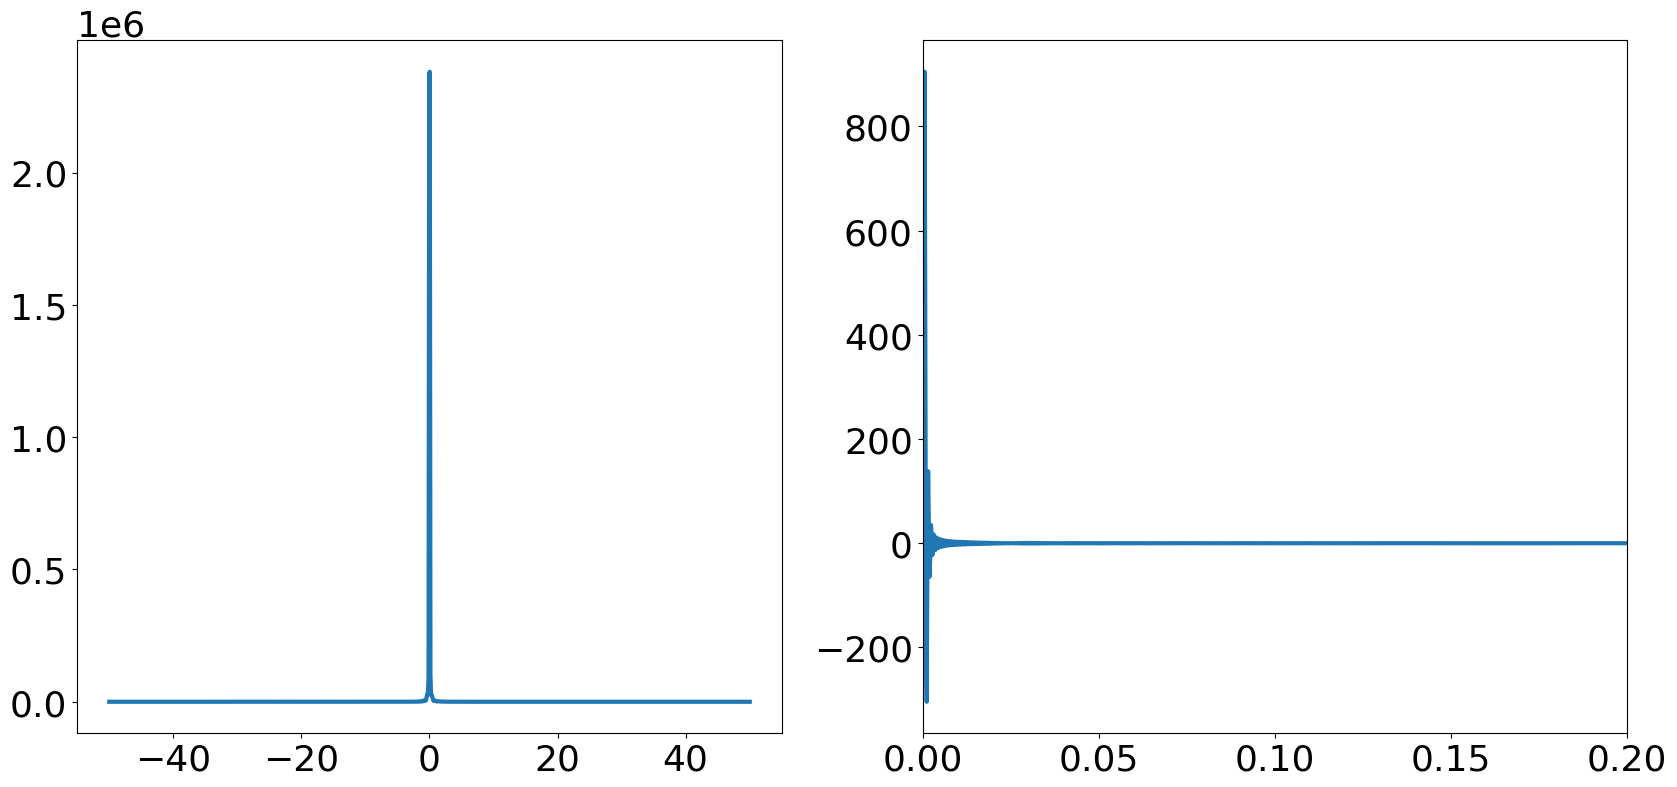

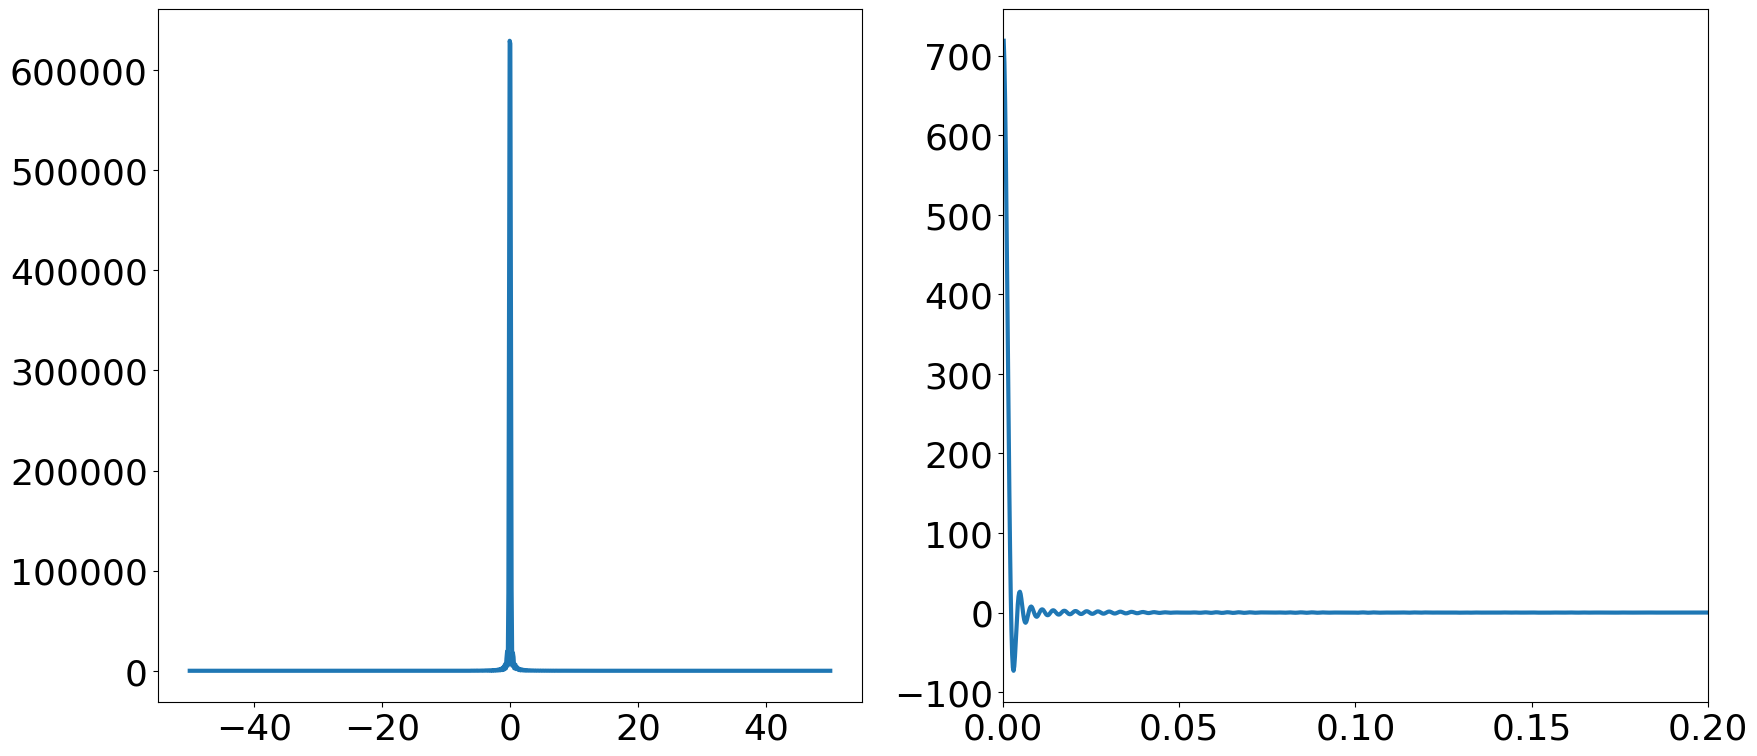

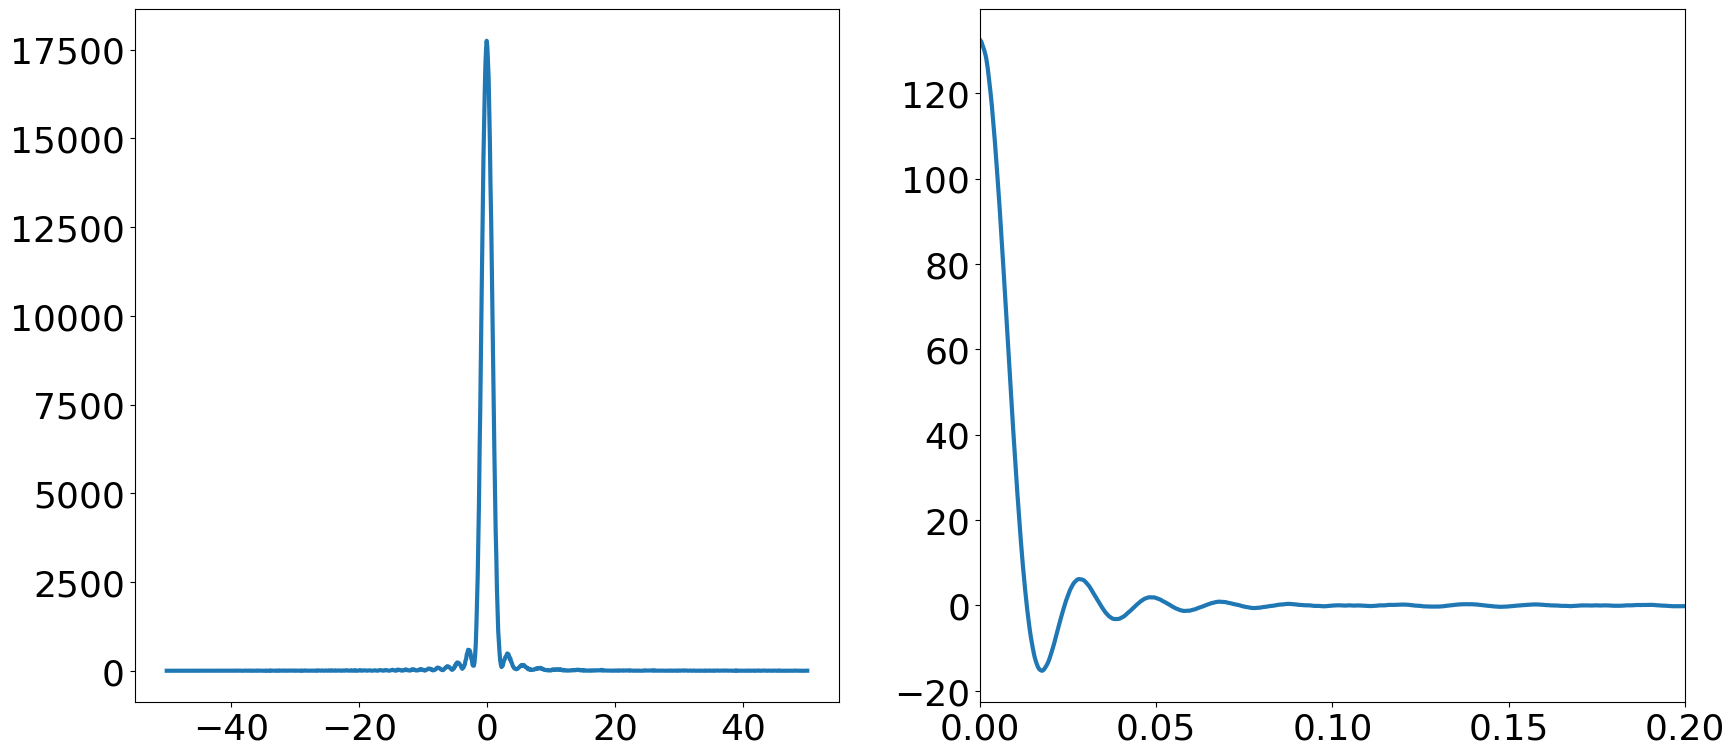

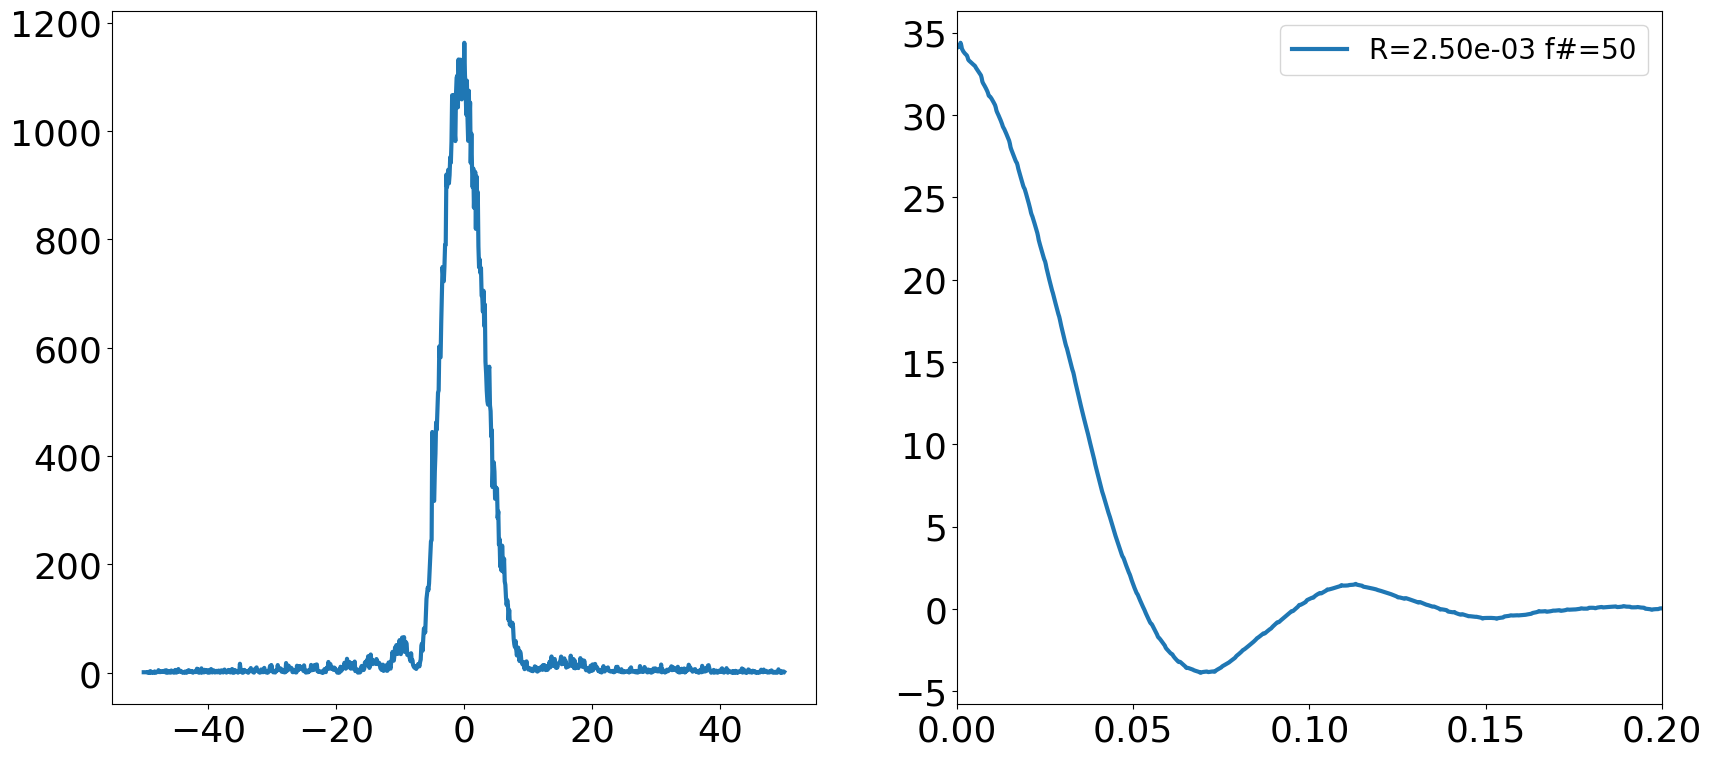

In [6]:
for i in range(len(fn)):
    # Define Hankel Parameters
    [r, k] = DHTarrays(nr, R[i], ell)
    [T_R2K, T_K2R] = DHTtransformMatrix(nr, R[i], ell)

    # Initial field
    phi_I=1j*np.exp(-((r / (R[i])) ** 8))
    z_mir=create_axiparabola(r,R[i],L,f)

    z=np.linspace(f-0.5,f+0.5,1000)

    ftf=forward_propagation(k, phi_I, T_R2K, T_K2R, z, z_mir, wl)

    #subplot side by side
    fig, ax = plt.subplots(1, 2)
    ax[0].plot((z-f)*100, np.abs(ftf[0,:])**2, label="R=%.2e f#=%d" % (R[i],fn[i]))
    
    ax[1].plot(r/R[i], np.real(ftf[:, len(z)//2]), label="R=%.2e f#=%d" % (R[i],fn[i]))
    ax[1].set_xlim([0, 0.2])

plt.legend()
plt.show()